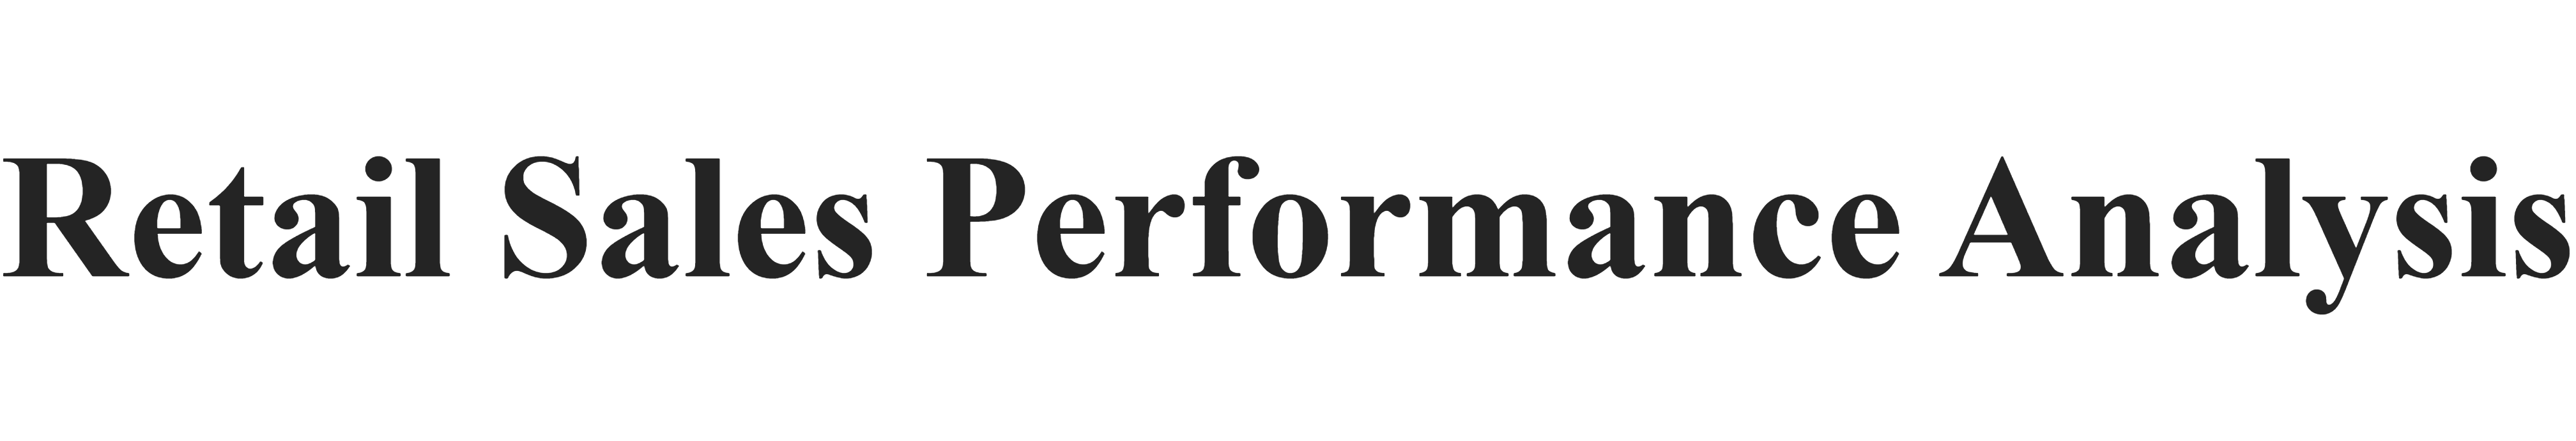

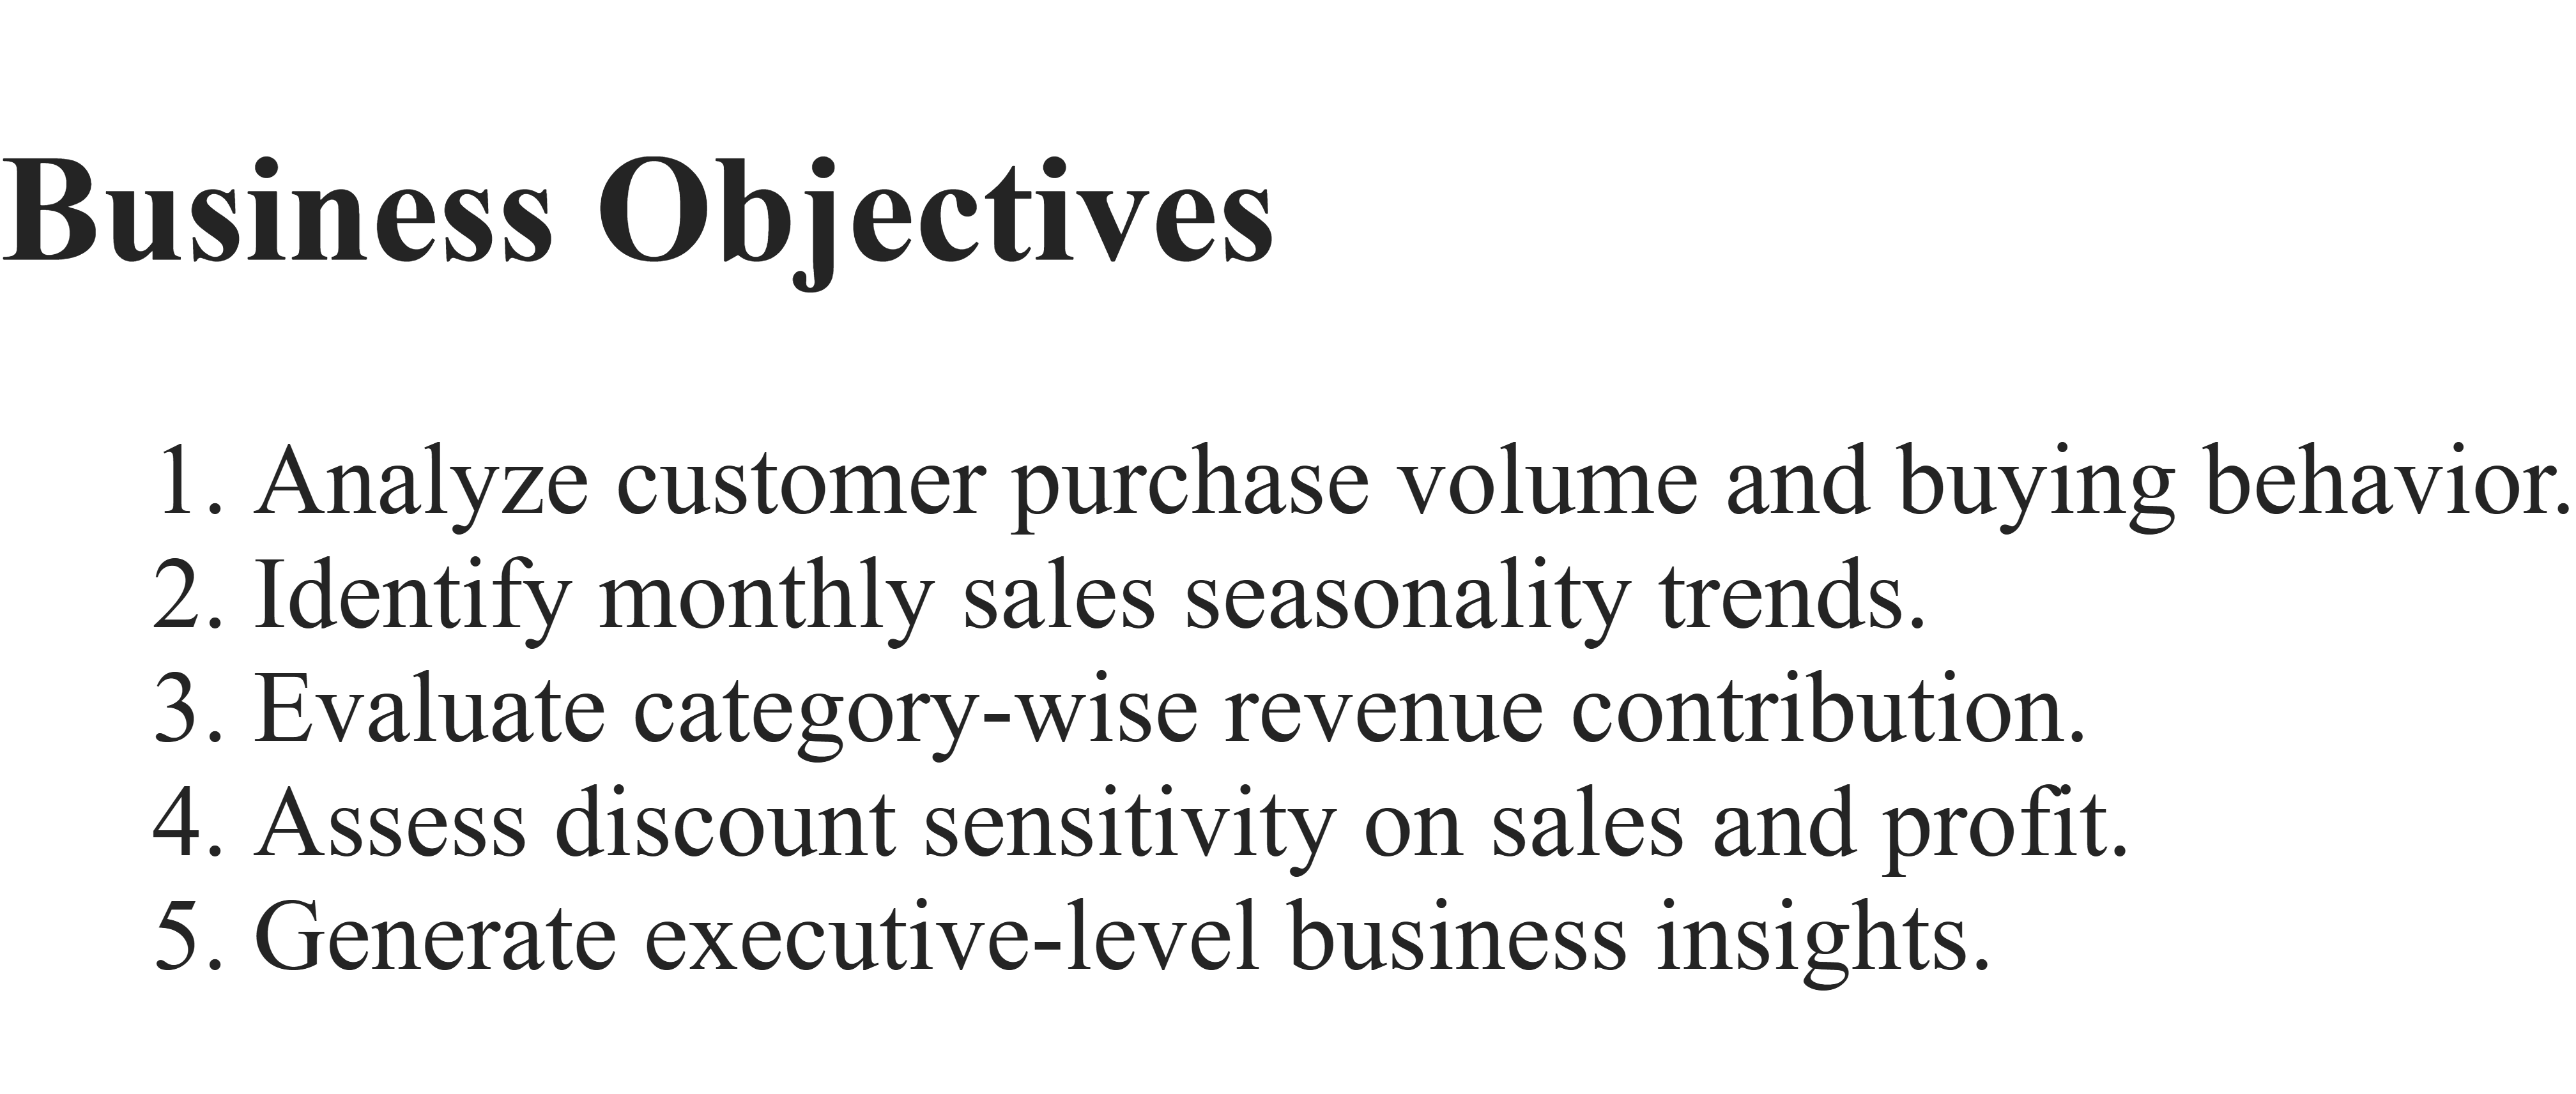

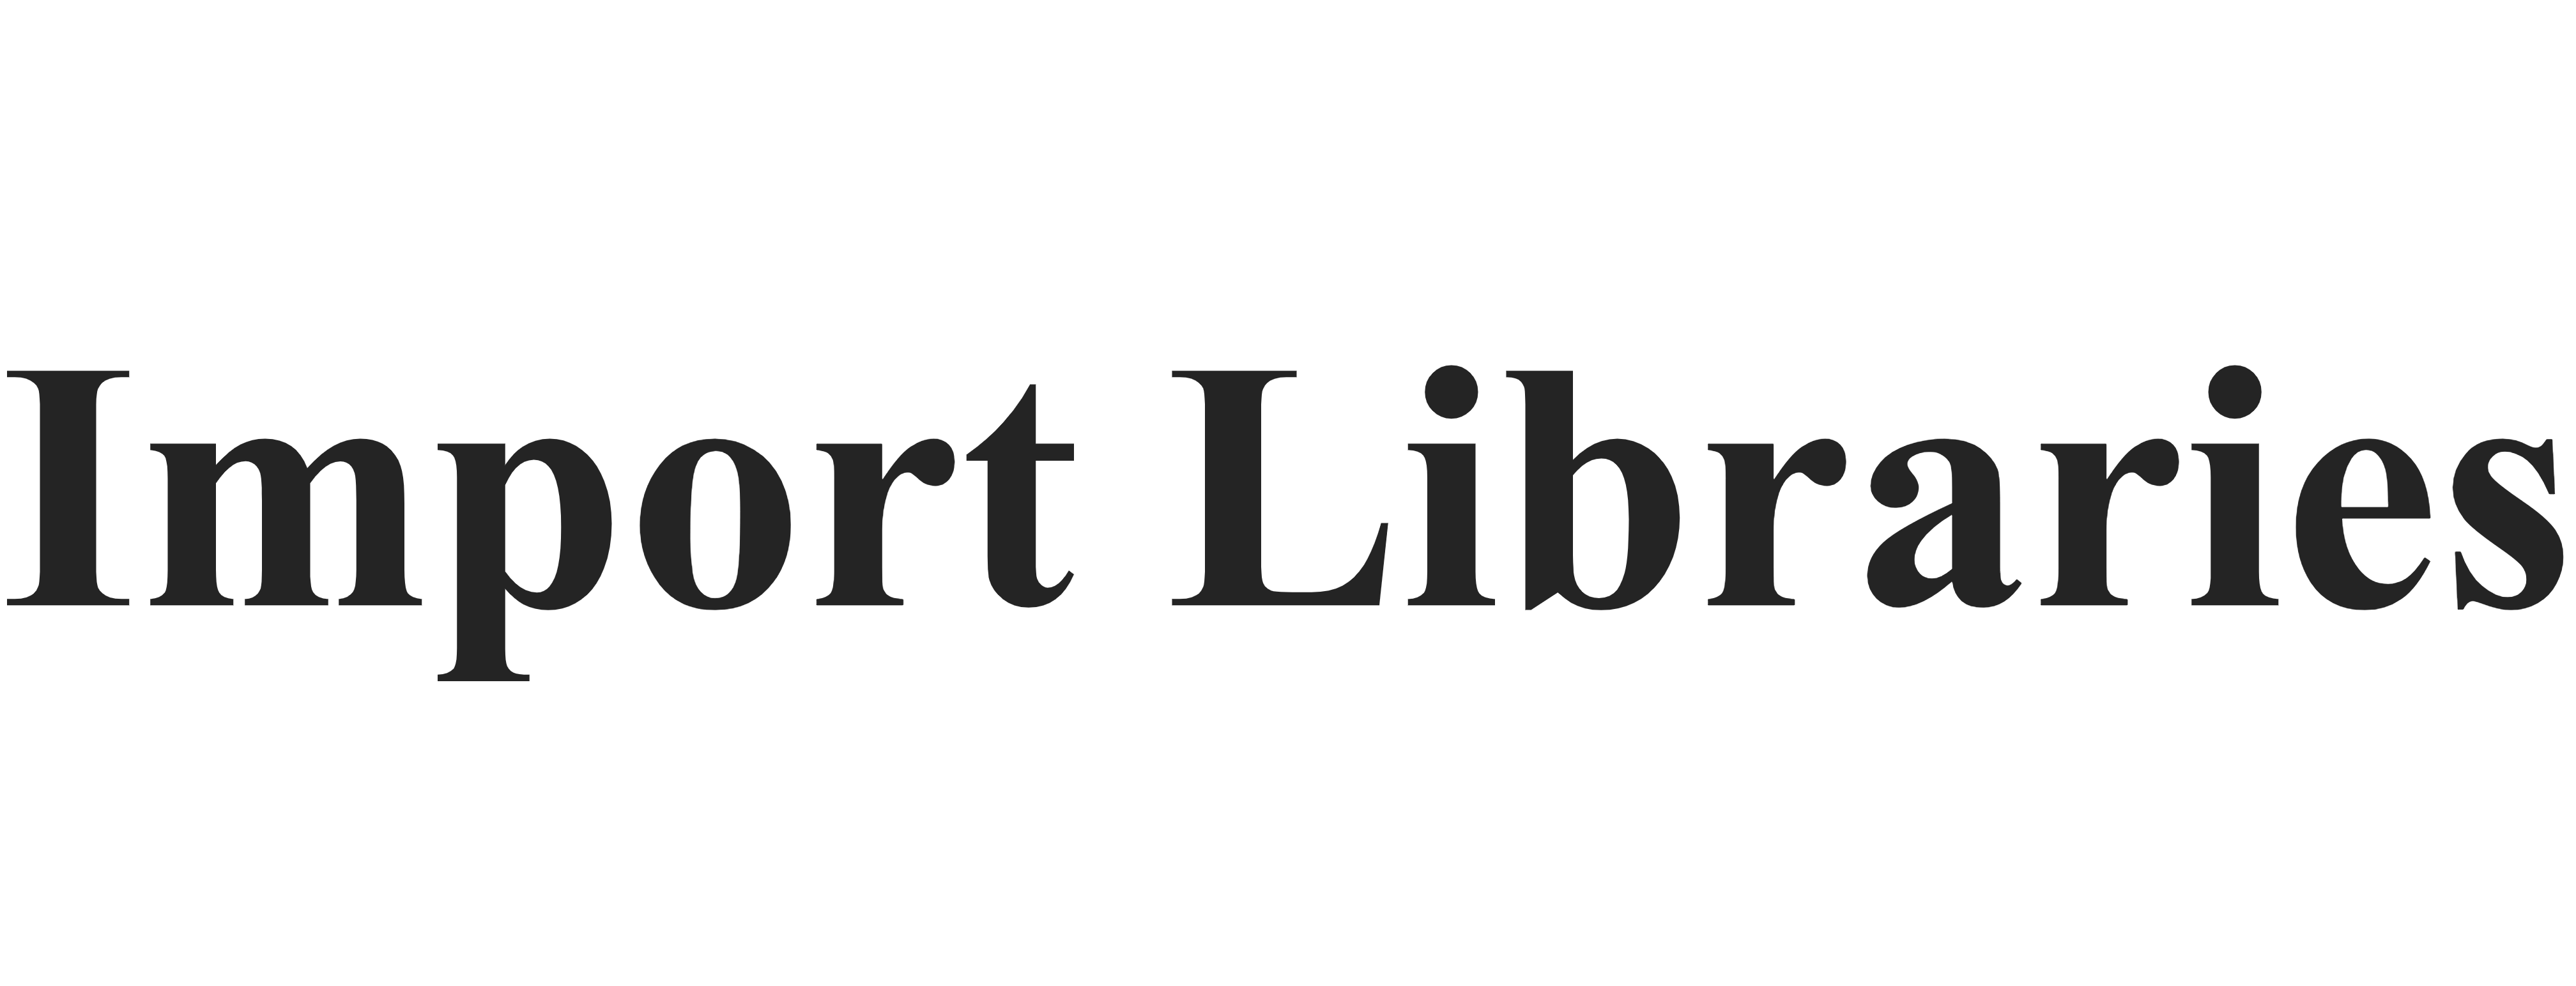

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

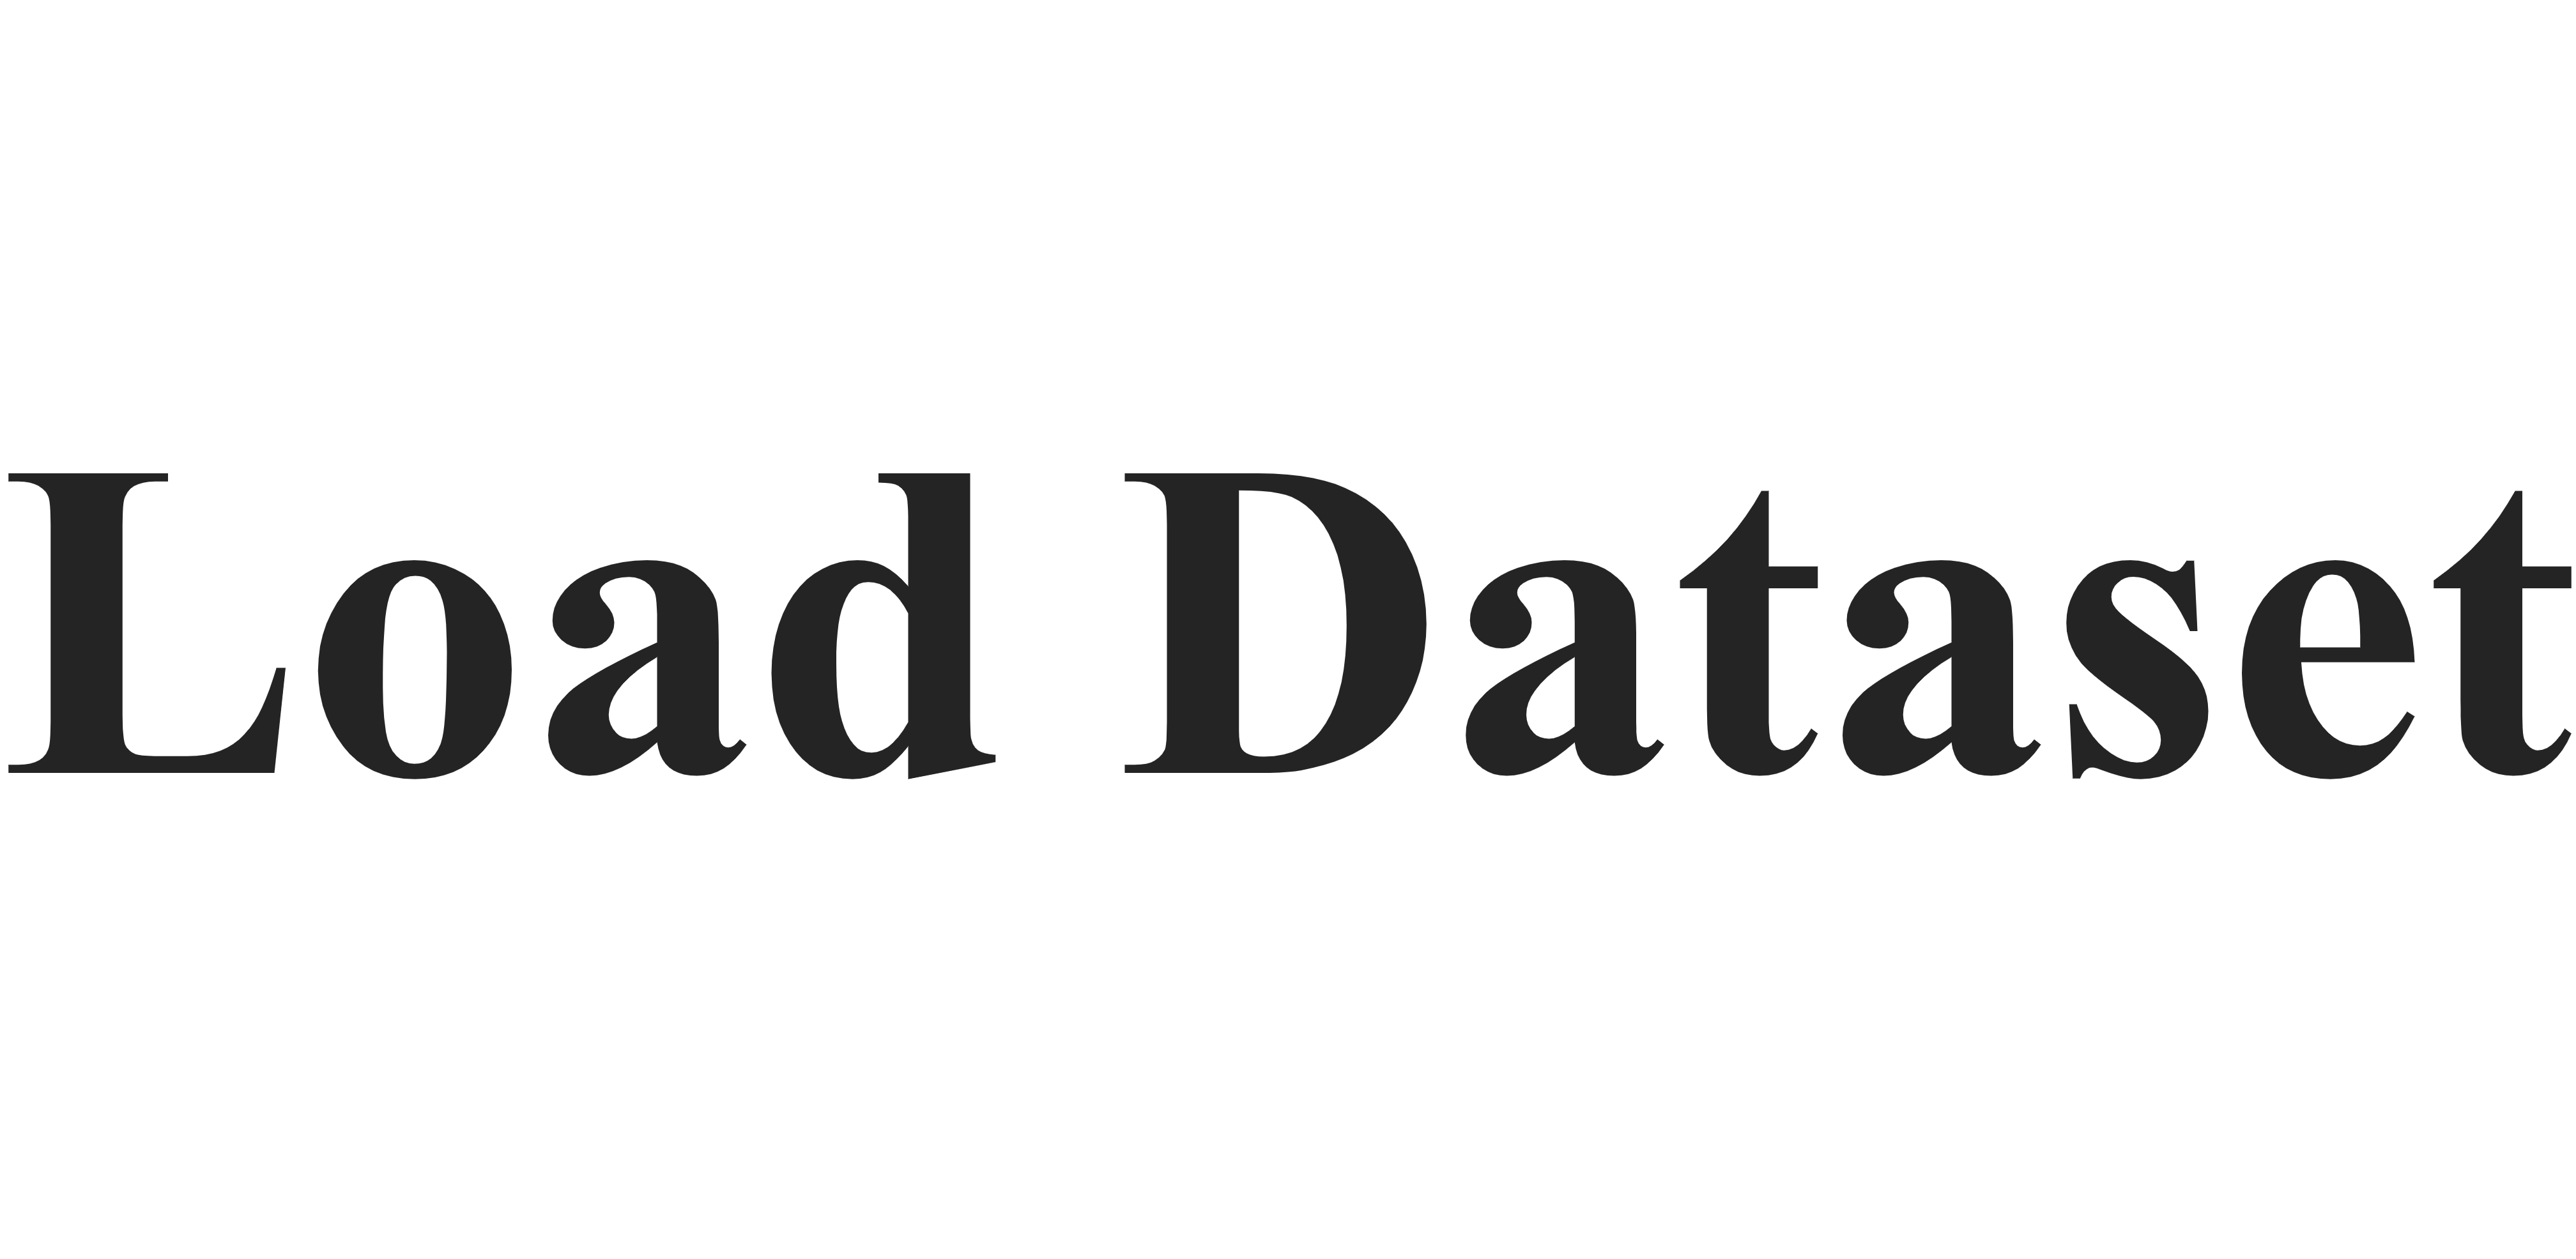

In [3]:
df=pd.read_csv(r"C:\Users\L\Downloads\superstore_sales.csv")

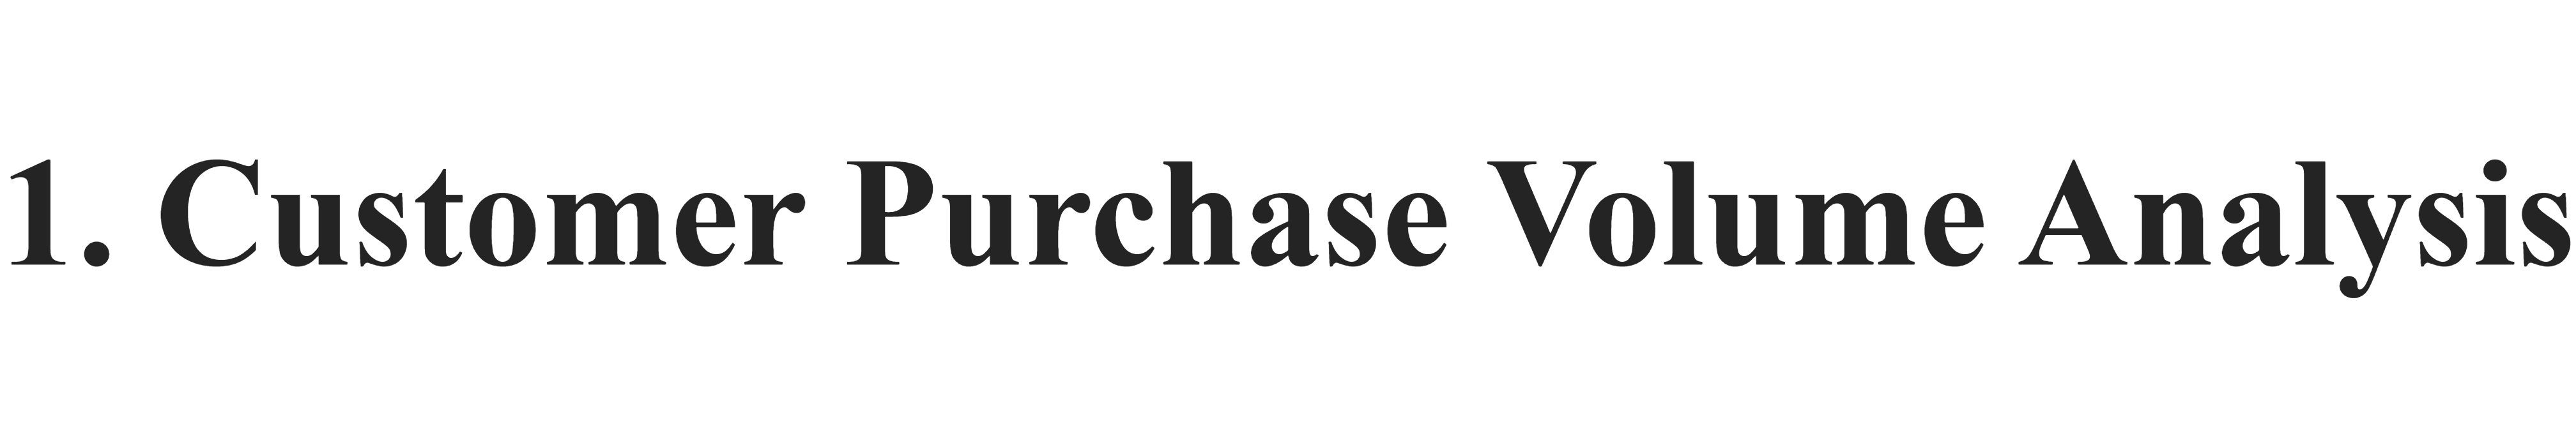

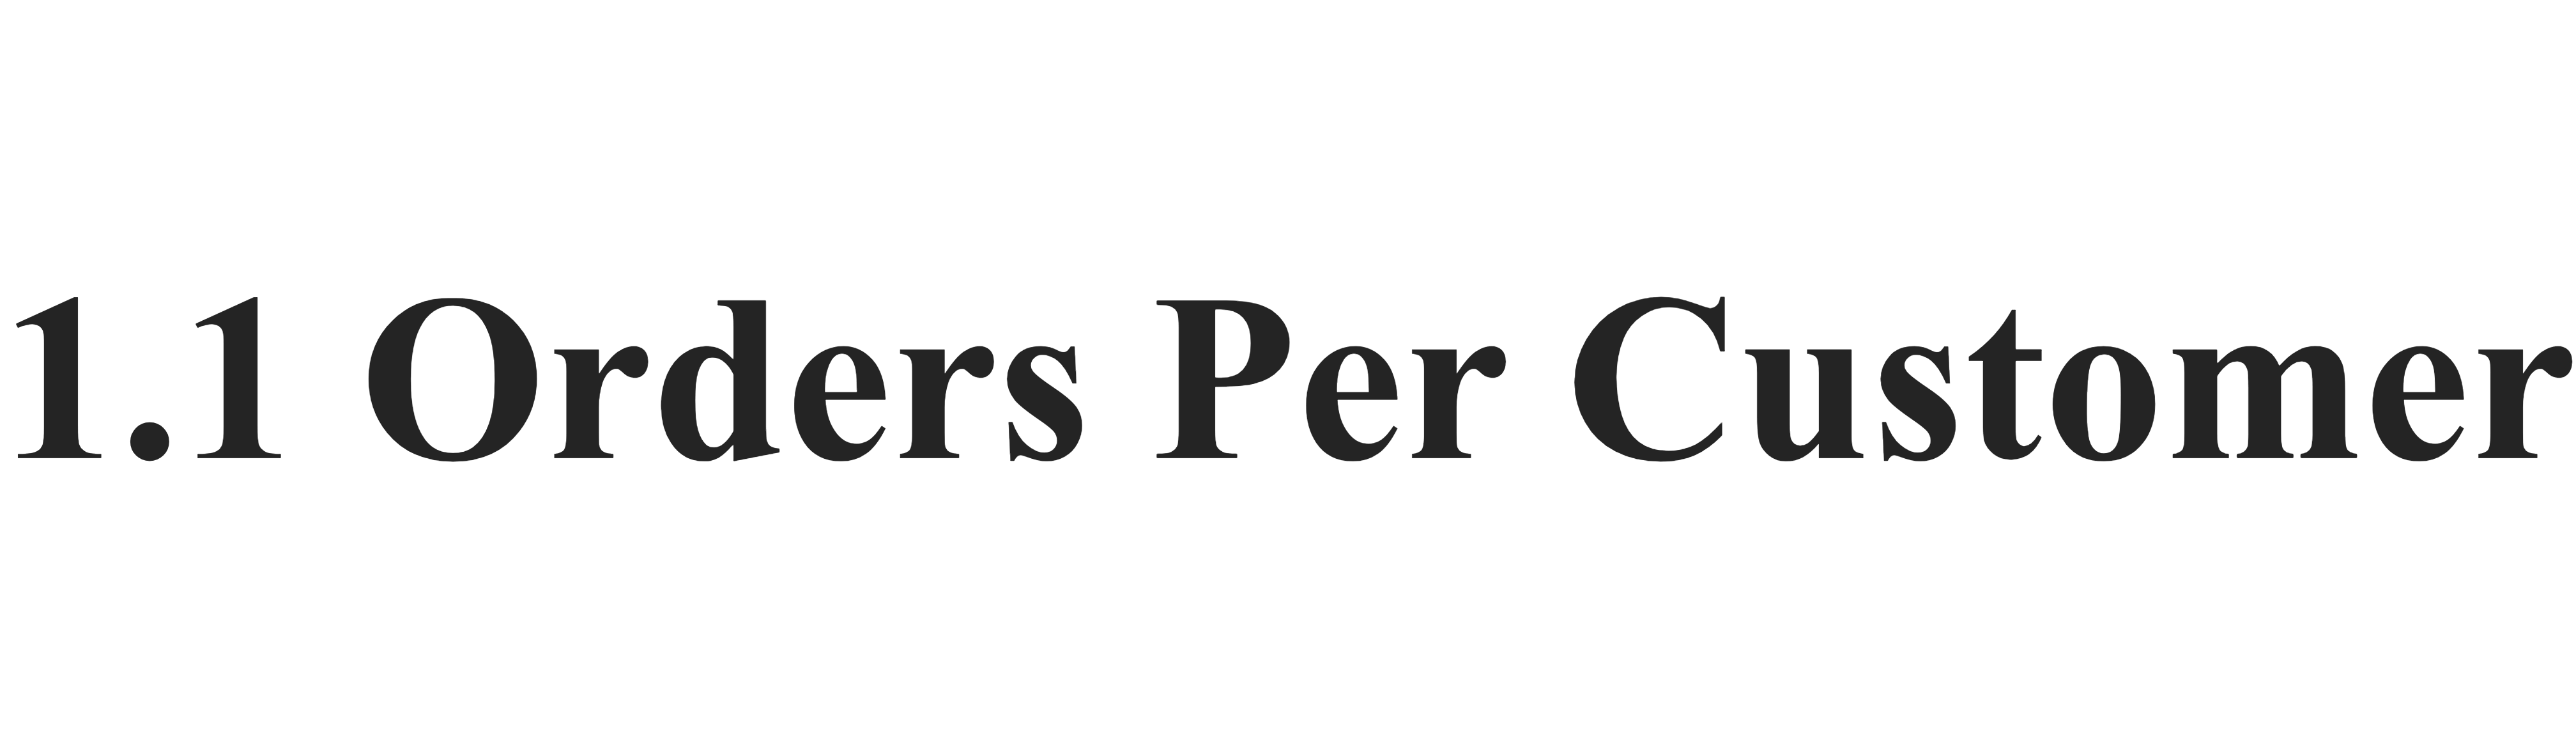

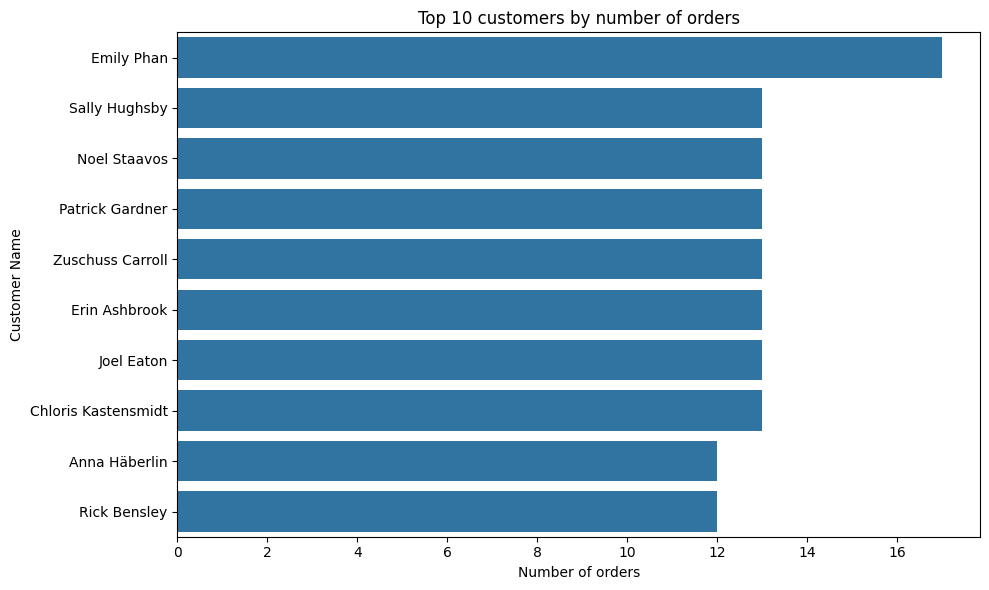

In [4]:
customer_orders=(df.groupby(["Customer ID","Customer Name"])["Order ID"].nunique().sort_values(ascending=False))

customer_orders.head(10)

top_customers=customer_orders.head(10).reset_index()

plt.figure(figsize=(10,6))
sns.barplot(data=top_customers, x="Order ID", y="Customer Name")

plt.title("Top 10 customers by number of orders")
plt.xlabel("Number of orders")
plt.ylabel("Customer Name")
plt.tight_layout()
plt.show()

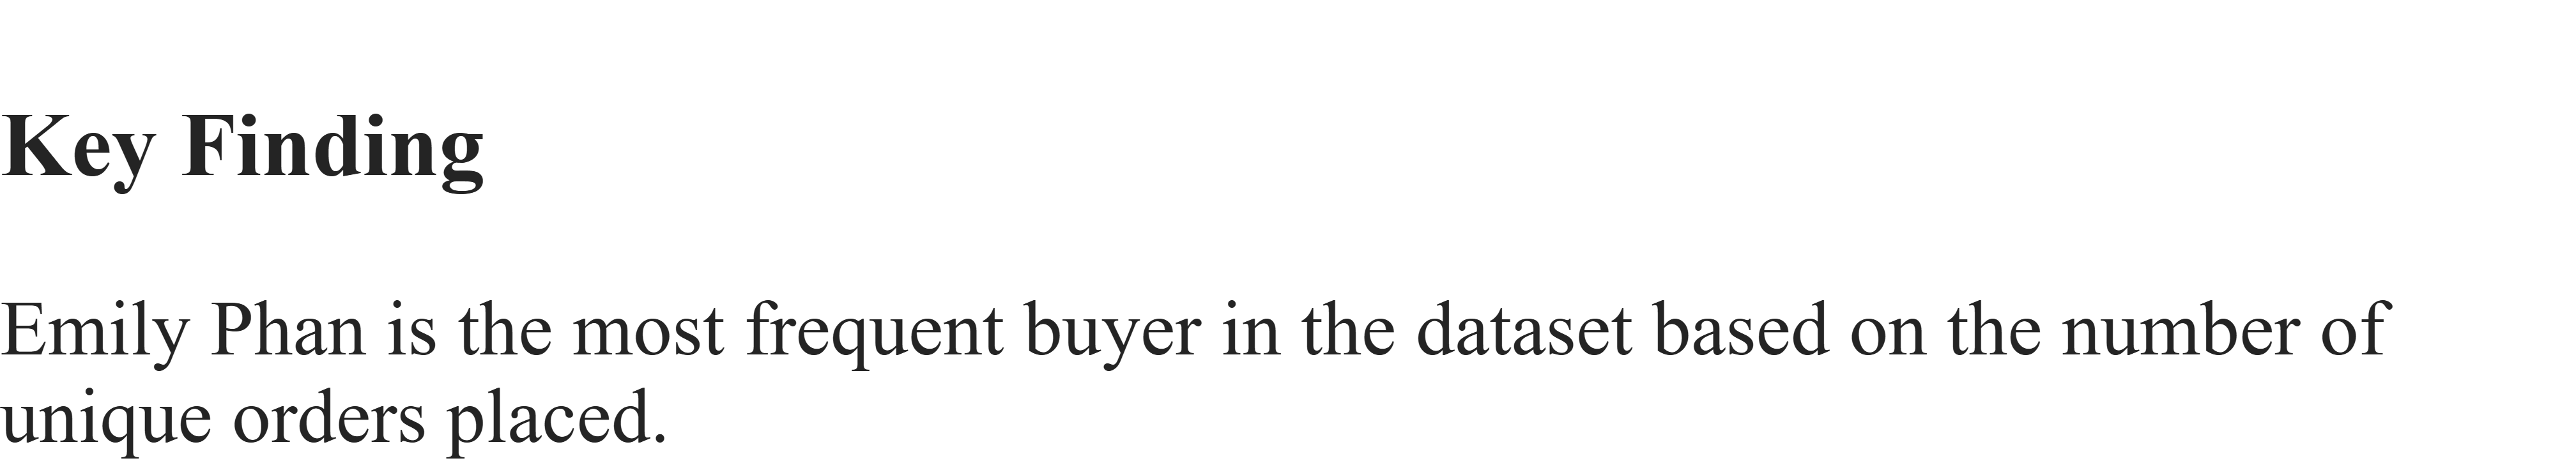

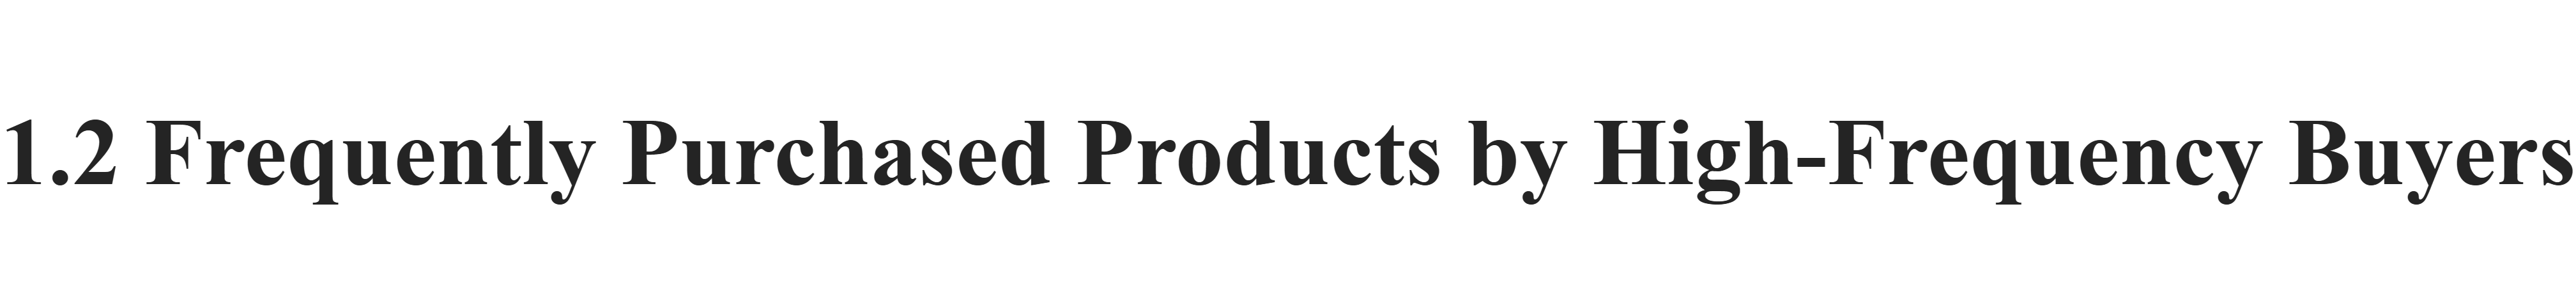

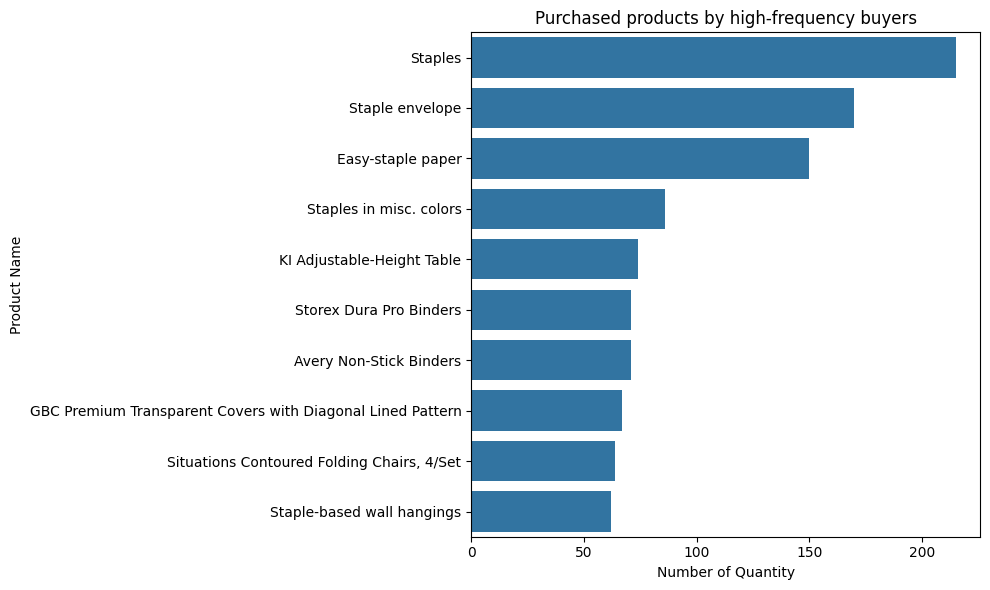

In [9]:
product_quantity=(df.groupby('Product Name')['Quantity'].sum().sort_values(ascending=False))

top_products=product_quantity.head(10).reset_index()

plt.figure(figsize=(10,6))

sns.barplot(data=top_products,x="Quantity",y="Product Name")
plt.title("Purchased products by high-frequency buyers")
plt.xlabel("Number of Quantity")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

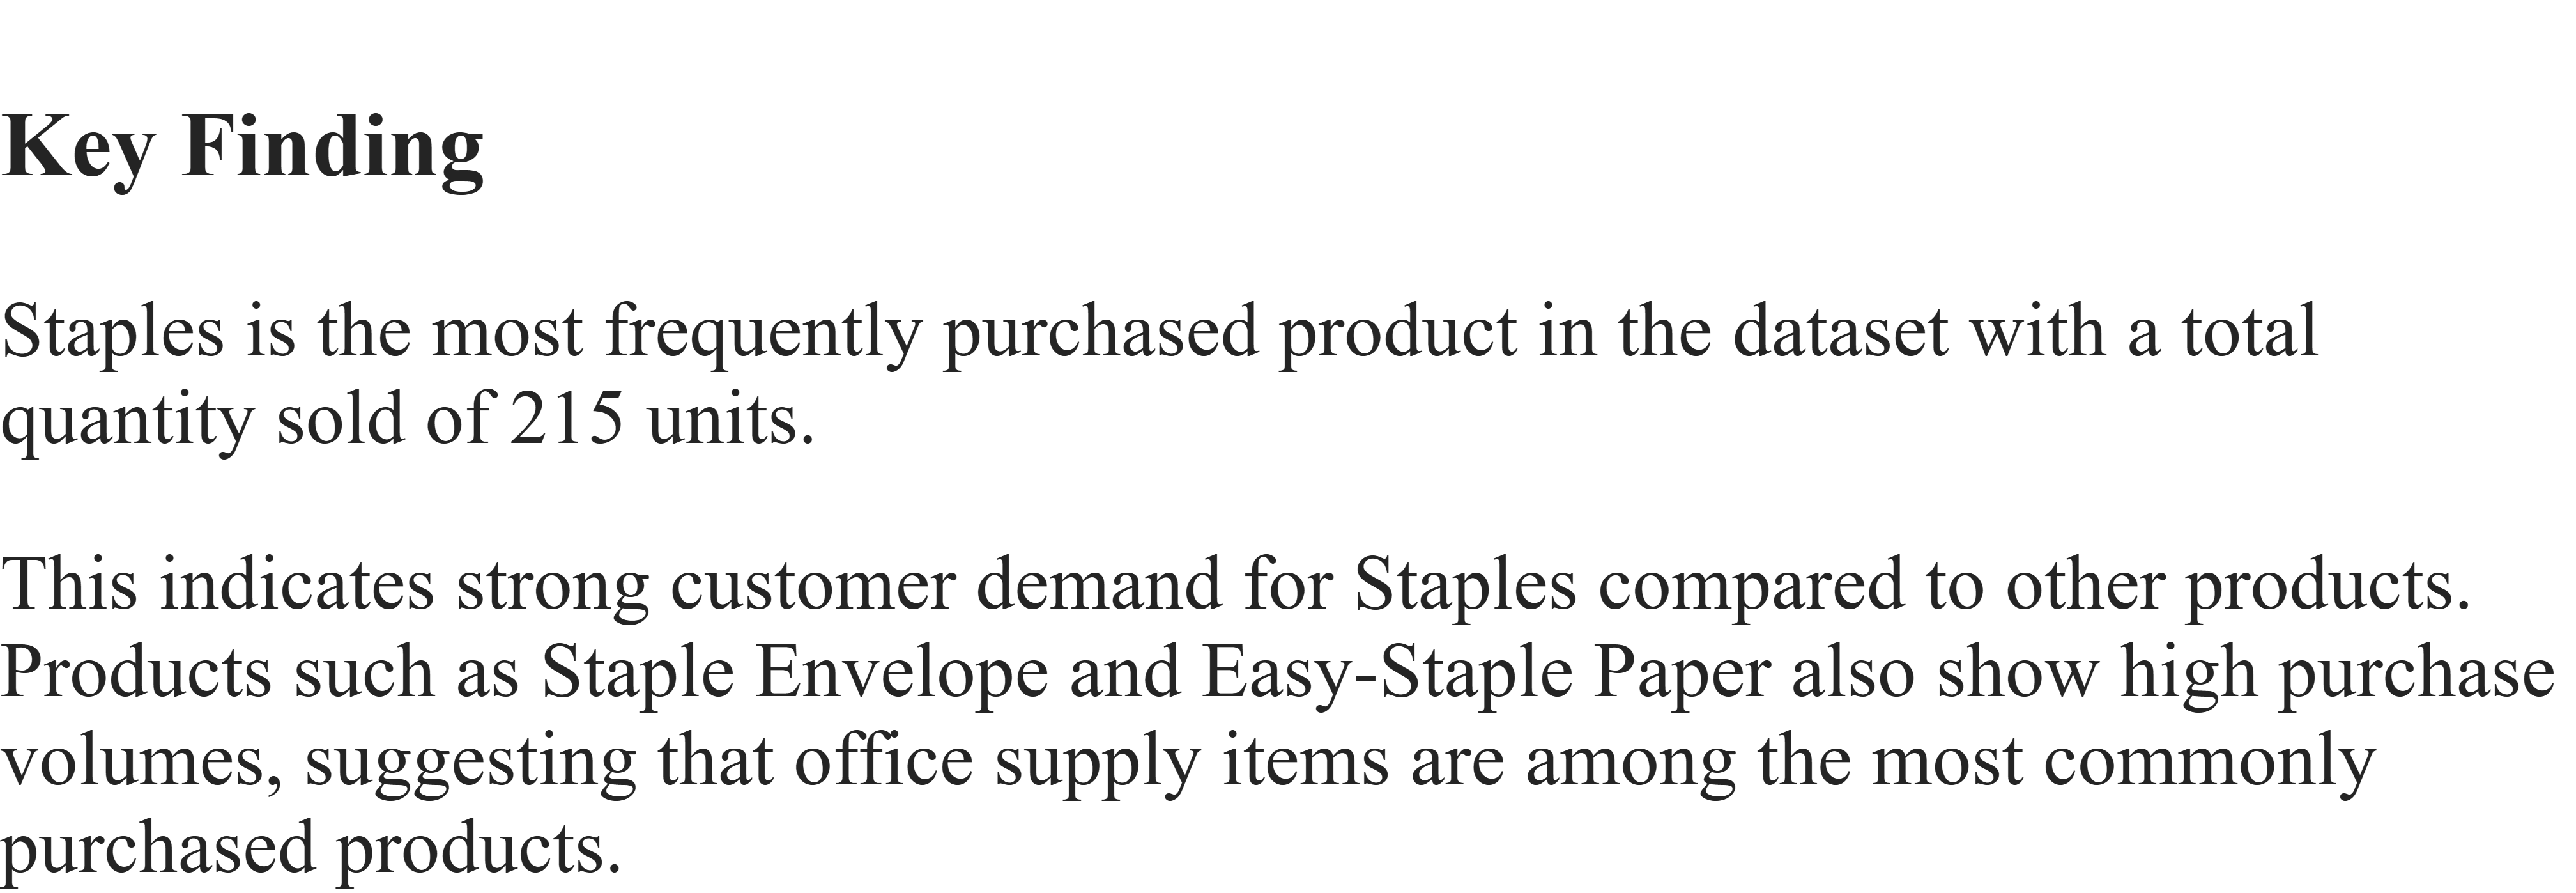

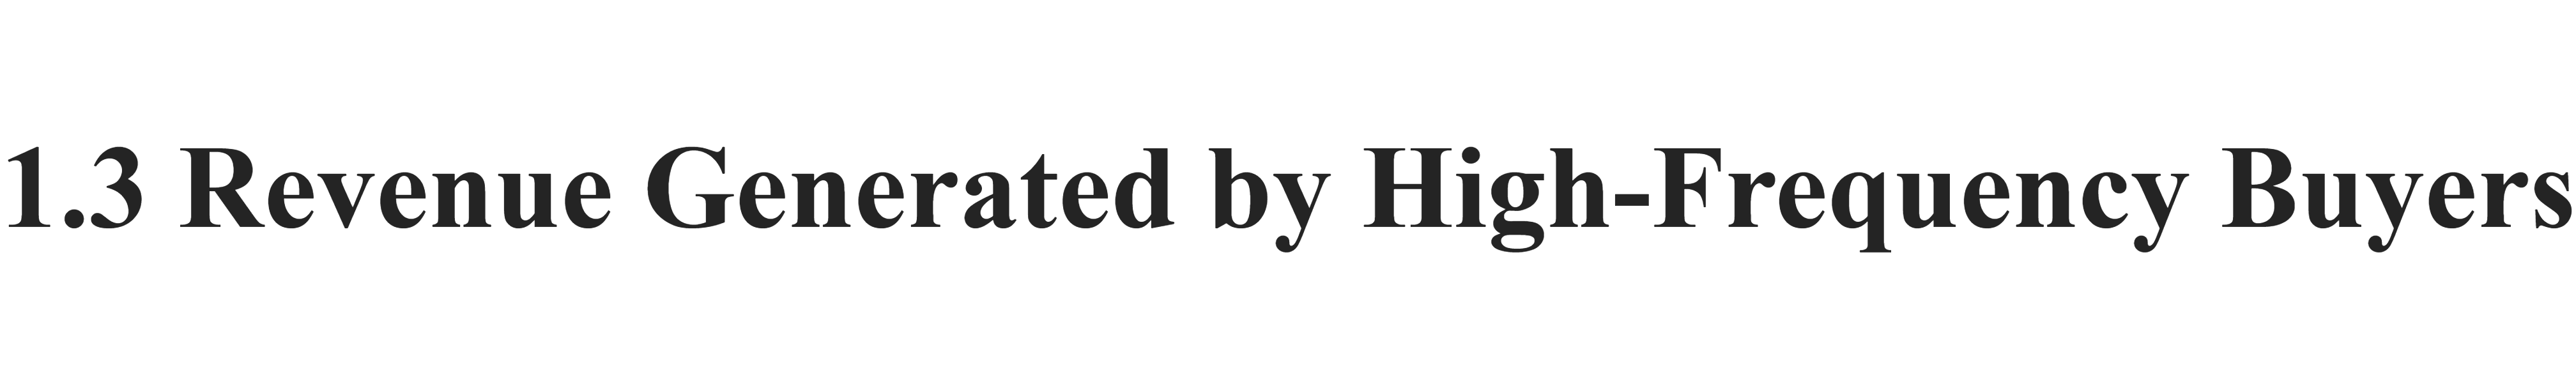

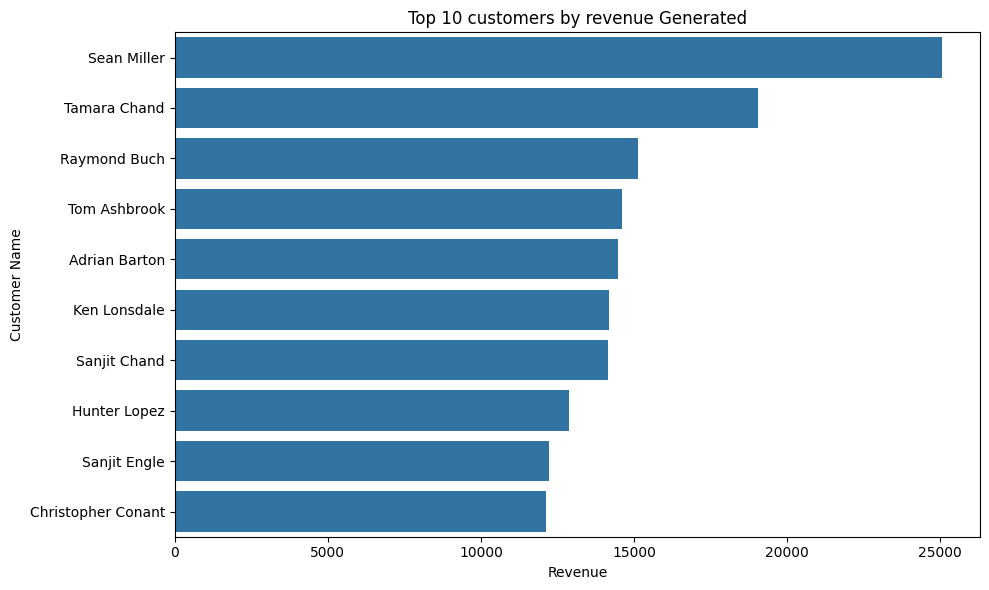

In [13]:
customer_revenue=(df.groupby(['Customer ID','Customer Name'])['Sales'].sum().sort_values(ascending=False))
customer_revenue.head(10)

top_customers_revenue=customer_revenue.head(10).reset_index() 

top_customers_revenue.head()

plt.figure(figsize=(10,6))

sns.barplot( data=top_customers_revenue, x="Sales", y="Customer Name")

plt.title("Top 10 customers by revenue Generated")
plt.xlabel("Revenue")
plt.ylabel("Customer Name")

plt.tight_layout()
plt.show()


Key Finding

The customer Sean Miller  generated the highest revenue among all customers in the dataset.


This indicates that although some customers place orders frequently, the customers contributing the highest revenue are the most valuable to the business and should be prioritized for retention and relationship-building strategies.

2. Monthly Seasonality Analysis

Objective

Analyze how sales and orders vary across different months and identify seasonal patterns.

2.1 Monthly Sales Trend

In [19]:
df["Order Date"]=pd.to_datetime(df["Order Date"])
df["Month"]=df["Order Date"].dt.month_name()
df[["Order Date","Month"]].head()

,Order Date,Month
0,2017-11-08,November
1,2017-11-08,November
2,2017-06-12,June
3,2016-10-11,October
4,2016-10-11,October


In [21]:
df["Month_Number"]=df["Order Date"].dt.month

monthly_sales=(df.groupby(["Month_Number","Month"])["Sales"].sum().reset_index().sort_values("Month_Number"))

monthly_sales

,Month_Number,Month,Sales
0,1.0,January,94924.8356
1,2.0,February,59751.2514
2,3.0,March,205005.4888
3,4.0,April,137762.1286
4,5.0,May,155028.8117
5,6.0,June,152718.6793
6,7.0,July,147238.0970
7,8.0,August,159044.0630
8,9.0,September,307649.9457
9,10.0,October,200322.9847


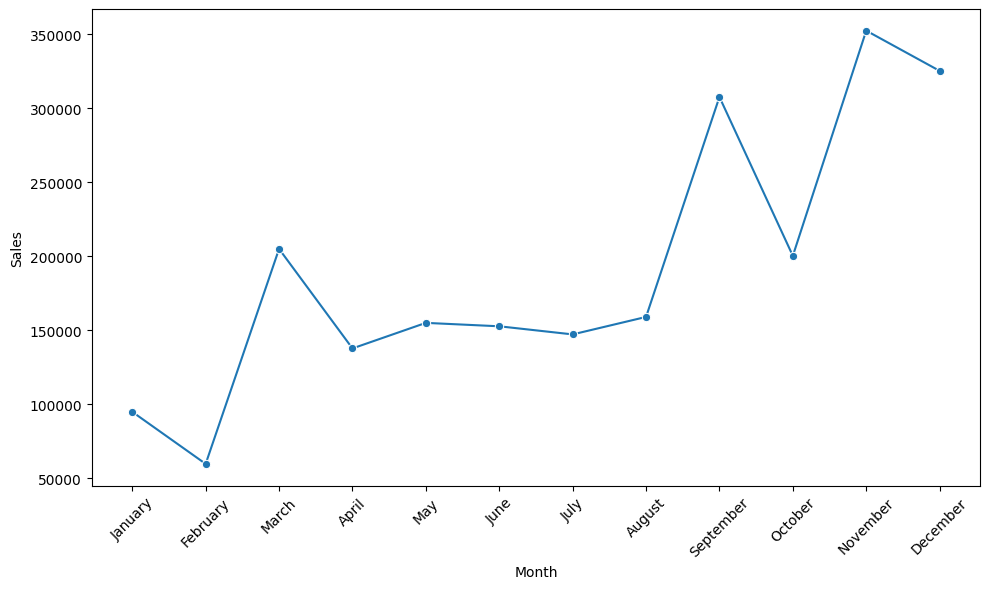

In [22]:
plt.figure(figsize=(10,6))

sns.lineplot(data=monthly_sales, x="Month", y="Sales", marker="o")
plt.xlabel("Month")
plt.ylabel("Sales")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [23]:
monthly_sales.sort_values("Sales", ascending=False).head()

,Month_Number,Month,Sales
10,11.0,November,352461.0710
11,12.0,December,325293.5035
8,9.0,September,307649.9457
2,3.0,March,205005.4888
9,10.0,October,200322.9847


Insights

1. November generated the highest sales among all months.

2. October recorded the lowest sales.

3. Sales showed a significant increase during November, indicating a seasonal demand pattern.

4. The business should ensure sufficient inventory and marketing campaigns before peak-demand months.

2.2 Monthly Order Volume 

In [25]:
monthly_orders=(df.groupby(["Month_Number","Month"])["Order ID"].nunique().reset_index().sort_values("Month_Number"))
monthly_orders

,Month_Number,Month,Order ID
0,1.0,January,178
1,2.0,February,162
2,3.0,March,354
3,4.0,April,343
4,5.0,May,369
5,6.0,June,364
6,7.0,July,338
7,8.0,August,341
8,9.0,September,688
9,10.0,October,417


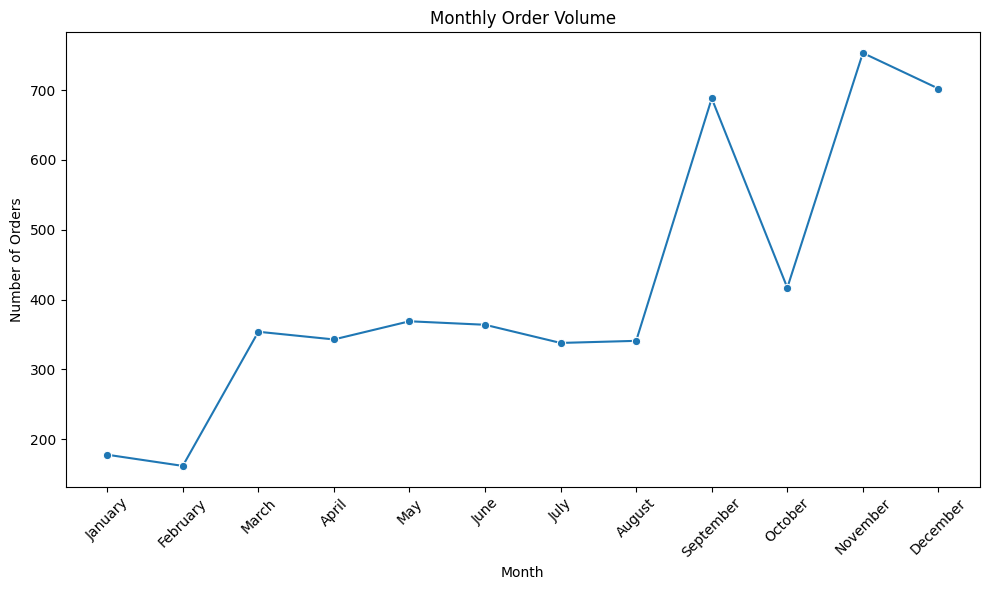

In [26]:
plt.figure(figsize=(10,6))

sns.lineplot(data=monthly_orders, x="Month", y="Order ID", marker="o")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
monthly_orders.sort_values("Order ID", ascending=False)

,Month_Number,Month,Order ID
10,11.0,November,753
11,12.0,December,702
8,9.0,September,688
9,10.0,October,417
4,5.0,May,369
5,6.0,June,364
2,3.0,March,354
3,4.0,April,343
7,8.0,August,341
6,7.0,July,338


Insights  

1. November recorded the highest order volume, indicating strong customer demand during this period.

2. February had the lowest order volume, suggesting weaker customer activity compared to other months.

3. The order volume trend closely follows the monthly sales trend, indicating that increased sales are primarily driven by a higher number of customer orders rather than unusually large individual orders.

4. The business should prepare inventory and marketing campaigns ahead of high-demand periods such as November to maximize revenue opportunities.

2.3 Monthly Profit Trend                                                                                                                                                                     

In [28]:
monthly_profit=(df.groupby(["Month_Number","Month"])["Profit"].sum().reset_index().sort_values("Month_Number"))
monthly_profit

,Month_Number,Month,Profit
0,1.0,January,9134.4461
1,2.0,February,10294.6107
2,3.0,March,28594.6872
3,4.0,April,11587.4363
4,5.0,May,22411.3078
5,6.0,June,21285.7954
6,7.0,July,13832.6648
7,8.0,August,21776.9384
8,9.0,September,36857.4753
9,10.0,October,31784.0413


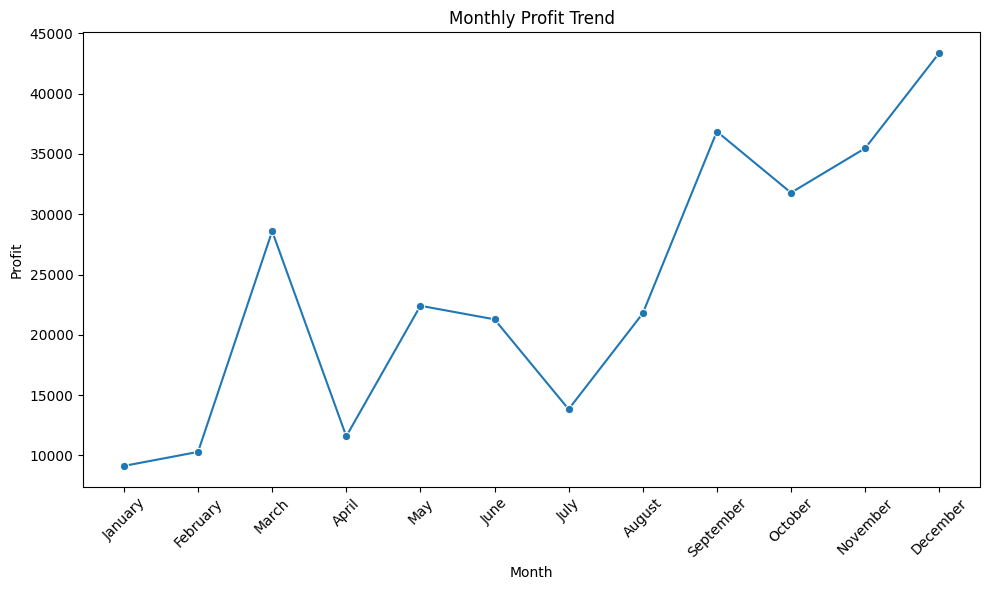

In [29]:
plt.figure(figsize=(10,6))

sns.lineplot(data=monthly_profit, x="Month", y="Profit", marker="o")

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Insights

1. January generated the highest profit among all months, indicating strong profitability during the beginning of the year.

2. December recorded the lowest profit, despite being a high-sales period.

3. Profit does not follow the same trend as sales. While some months generate high sales, they do not necessarily generate high profit.

4. This suggests that factors such as discounts, product mix, shipping costs, or operational expenses may impact profitability.

5. The business should focus not only on increasing sales but also on improving profit margins during high-sales periods.


3. Category-wise Revenue Analysis

In [12]:
category_revenue=( df.groupby("Category")["Sales"].sum().sort_values(ascending=False)) 
category_revenue

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64

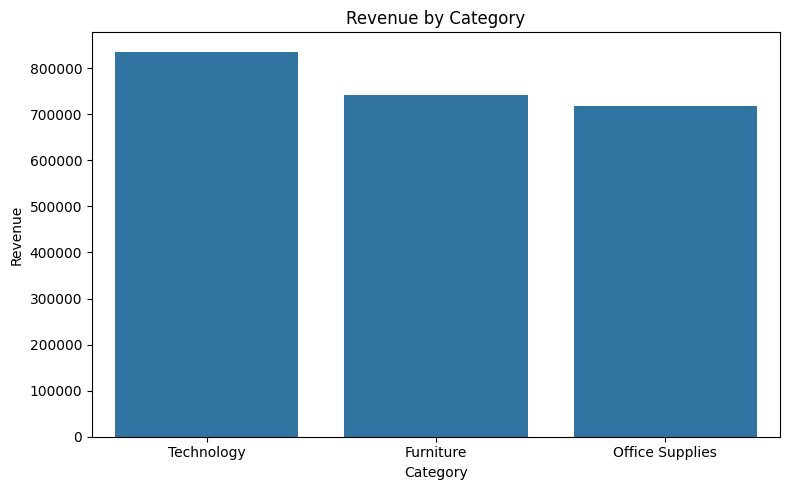

In [9]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=top_categories,
    x="Category",
    y="Sales"
)
plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()

Insights for Report

1. Technology is the highest revenue-generating category, contributing approximately 836,154 in sales.

2. Office Supplies generated the lowest revenue among the three categories.

3. Technology products appear to have strong customer demand and contribute significantly to overall business revenue.

4. The business should continue investing in Technology products through targeted promotions and inventory planning.

5. Although Furniture and Office Supplies contribute substantial revenue, their performance remains below the Technology category.



4. Discount Sensitivity Analysis

4.1 Impact of Discount on Sales

In [13]:
discount_sales=(df.groupby("Discount")["Sales"].mean().reset_index()) 
discount_sales

,Discount,Sales
0,0.00,226.742074
1,0.10,578.397351
2,0.15,529.971567
3,0.20,209.076940
4,0.30,454.742974
5,0.32,536.794770
6,0.40,565.134874
7,0.45,498.634000
8,0.50,892.705152
9,0.60,48.150000


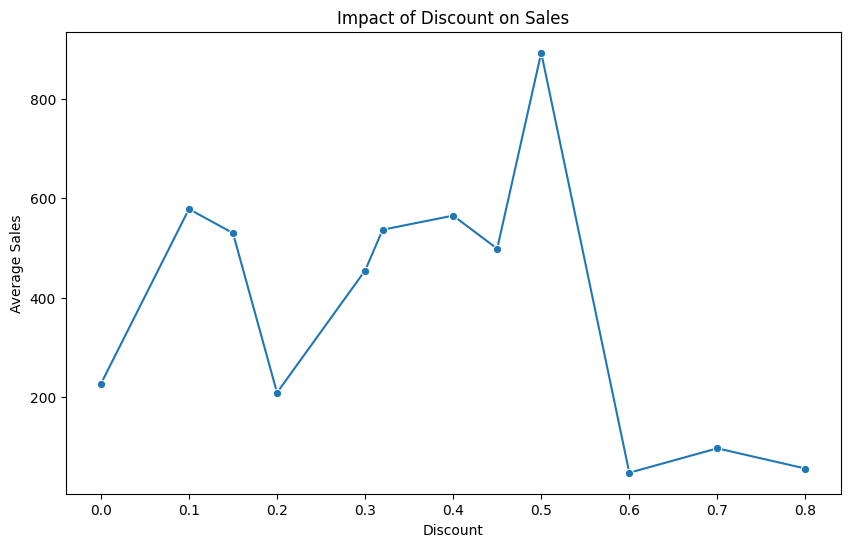

In [14]:
plt.figure(figsize=(10,6))
sns.lineplot(data=discount_sales, x="Discount",y="Sales",marker="o")
plt.title("Impact of Discount on Sales")
plt.xlabel("Discount")
plt.ylabel("Average Sales")
plt.show()

Insights
1. Products sold without any discount (0.00 discount level) generated the highest average sales.

2. The 0.10 discount level recorded the lowest average sales among all discount levels.

3. Sales generally increase as discounts are offered, indicating that customers are price-sensitive and respond positively to promotional offers.

4. Discounts appear to encourage purchasing behavior and can help improve sales volume.

5. However, higher sales do not necessarily guarantee higher profitability, which should be analyzed separately through profit analysis.

4.2 Impact of Discount on Quantity Purchased

In [16]:
discount_quantity=(df.groupby("Discount")["Quantity"].mean().reset_index())
discount_quantity

,Discount,Quantity
0,0.00,3.807211
1,0.10,3.968085
2,0.15,3.807692
3,0.20,3.735302
4,0.30,3.740088
5,0.32,3.888889
6,0.40,3.815534
7,0.45,4.090909
8,0.50,3.651515
9,0.60,3.630435


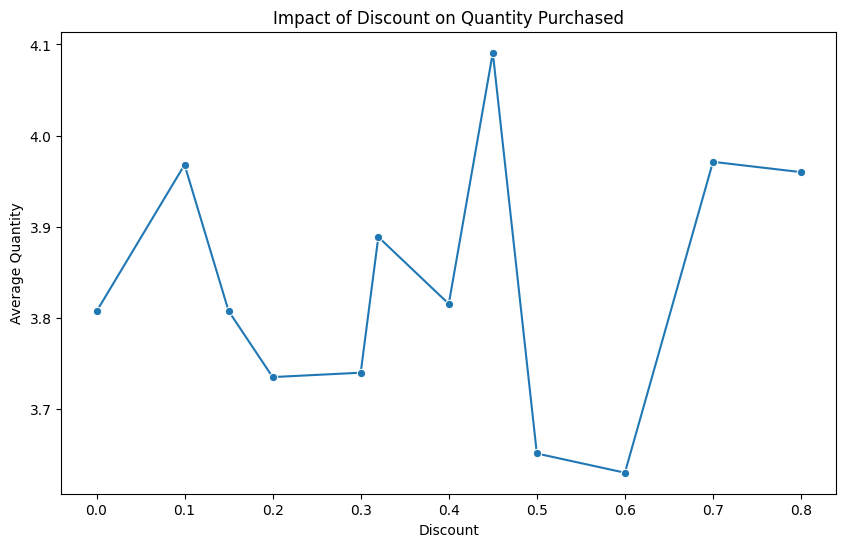

In [17]:
plt.figure(figsize=(10,6))
sns.lineplot(data=discount_quantity, x="Discount", y="Quantity", marker="o")
plt.title("Impact of Discount on Quantity Purchased")
plt.xlabel("Discount")
plt.ylabel("Average Quantity")
plt.show()

Insights
1. Orders with no discount (0.00 discount level) recorded the highest average quantity purchased.

2. The 0.80 discount level recorded the lowest average quantity purchased.

3. Customer purchasing behavior does not appear to increase consistently with higher discount levels.

4. While discounts may influence purchasing decisions, other factors such as product demand, category, and customer preferences also affect quantity purchased.

5. The business should evaluate discount strategies carefully rather than assuming higher discounts will always lead to higher purchase volumes.

4.3 Impact of Discount on Profit

In [4]:
discount_profit=(df.groupby("Discount")["Profit"].mean().reset_index())
discount_profit

,Discount,Profit
0,0.00,66.900292
1,0.10,96.055074
2,0.15,27.288298
3,0.20,24.702572
4,0.30,-45.679636
5,0.32,-88.560656
6,0.40,-111.927429
7,0.45,-226.646464
8,0.50,-310.703456
9,0.60,-43.077212


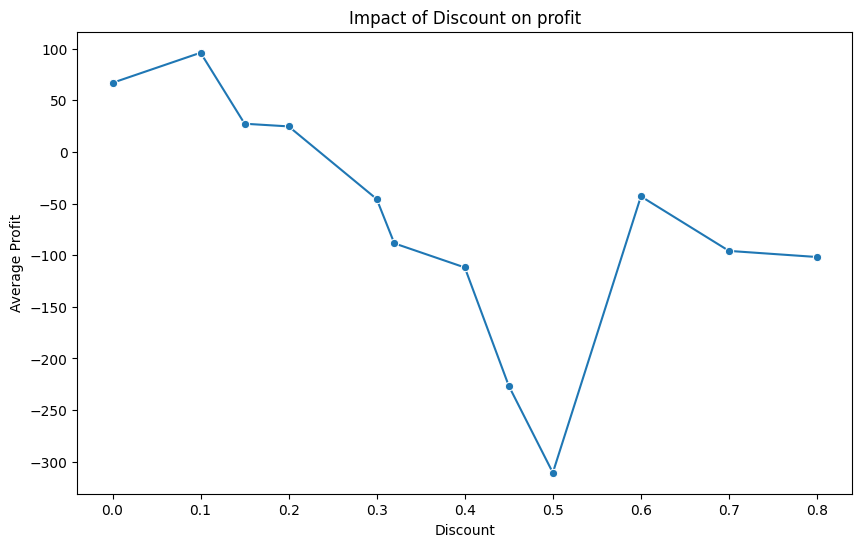

In [6]:
plt.figure(figsize=(10,6))
sns.lineplot(data=discount_profit, x="Discount", y="Profit", marker="o")
plt.title("Impact of Discount on profit")
plt.xlabel("Discount")
plt.ylabel("Average Profit")

plt.show()

Insights
1. Products sold without discounts (0.00 discount level) generated the highest average profit.

2. The 0.80 discount level recorded the lowest average profit among all discount levels.

3. Profit consistently decreased as discount levels increased.

4. While discounts may help improve sales volume, excessive discounting significantly reduces profitability.

5. High-discount strategies should be used carefully because they can generate additional sales at the cost of lower profit margins.

6. The company should focus on identifying an optimal discount level that balances sales growth and profitability.

Executive Takeaways
1. November recorded the highest sales and order volume, indicating strong seasonal demand during this period.

2. Technology was the highest revenue-generating category, contributing more revenue than Furniture and Office Supplies.

3. High-frequency buyers generated a significant portion of total business revenue, highlighting the importance of customer retention strategies.

4. Certain products were purchased substantially more frequently than others, suggesting opportunities for focused inventory planning and product promotion.

5. Discounts generally helped increase sales and customer purchasing activity.

6. Profitability decreased as discount levels increased, indicating that aggressive discounting can negatively impact business performance.

7. The company should focus on retaining high-value customers, investing in high-performing product categories, and maintaining discount levels that support both sales growth and profitability.